# Paper 13 — Two Voices, One Integrated Local Video

## Abstract

This notebook builds an original four-scene motion short, *One Small Light*, using two prepared local voices and contrasting emotional references. Each dialogue turn passes through the verified voice → master → neural enhancement chain before assembly. Visual movement, shot pacing and complete-turn captions follow measured processed audio. The study tests traceable integration and technical delivery, while separating intended emotion from perceived emotional fidelity. Results below are produced by execution, not assumed. No separate application interface is introduced.

## 1. Question, scope and critical test

Can the existing local audio engines support one coherent, timed two-character video with reproducible voice/emotion choices and preserved audio lineage?

**Hypothesis:** four individually generated and processed turns can be assembled with motion, readable captions and audible speech, without losing timing or substituting an unprocessed voice recording.

**Challenges:** reference emotion may not transfer; speakers may sound inconsistent; processing may damage pronunciation; a correctly encoded video may still be poorly paced. Technical success alone does not resolve these listening judgments.

**Failure criteria:** missing cast/emotion evidence, broken audio lineage, absent/silent dialogue, unreadable/overflowing captions, incorrect scene timing, decoding failures, or changes to prior papers/Money settings.

## 2. Production design

| Element | Deliberate choice |
|---|---|
| Story | A worried creator and a calm partner choose a manageable first step |
| Female voice | Mira, prepared speaker 0015: sadness → surprise |
| Male voice | Rowan, prepared speaker 0012: neutral → happiness |
| Audio standard | Balanced mastering followed by neural enhancement; one declared cue-specific compressor override after pilot failure |
| Picture | Original procedural illustration with lantern motion, parallax, changing path and camera-like composition |
| Timing | Measured enhanced speech; 0.35-second lead, at least 0.5-second release, frame-quantized scenes |
| Captions | Exact complete dialogue turn on screen; no word-level alignment claim |
| Music | Original quiet three-tone bed; speech remains foreground |
| Delivery | 1280 × 720, 24 fps, H.264 + AAC in MP4 |

The visuals are authored procedural animation, not diffusion-generated footage or lip-synced avatars. Labels show intended reference emotions, not a claim that listeners perceive them.

## 3. Editable script and cast

Change the following data to propose another run. Rendering and voice processing take real time and create a new isolated output folder.

In [1]:
from pathlib import Path
import sys, json, time
ROOT = Path('/Users/x/projects/swarms')
STUDY = ROOT / 'knowledge/research/paper-13-study'
sys.path.insert(0, str(STUDY))
import pipeline
story = {'title': 'One Small Light', 'voices': {'Mira': {'speaker_id': '0015', 'gender': 'female'}, 'Rowan': {'speaker_id': '0012', 'gender': 'male'}}, 'scenes': [{'speaker': 'Mira', 'emotion': 'sadness', 'headline': 'Too many possibilities', 'text': 'I keep collecting ideas, but none of them feels ready to begin.'}, {'speaker': 'Rowan', 'emotion': 'neutral', 'headline': 'Choose one small thing', 'text': 'Then let’s choose one small thing we can finish together, today.'}, {'speaker': 'Mira', 'emotion': 'surprise', 'headline': 'A light. A path. A first step.', 'text': 'Just one? A light, a path, and a first step?'}, {'speaker': 'Rowan', 'emotion': 'happiness', 'headline': 'Somewhere safe to start', 'text': 'Exactly. We don’t need the whole bridge. We need somewhere safe to start.'}]}
# Pilot: the short surprise turn was peak-limited; retain all other defaults.
story['scenes'][2]['master_overrides'] = {'ratio': 6, 'threshold_db': -30, 'attack_ms': 0.1, 'release_ms': 100}
pipeline.validate(story)
print(json.dumps(story, indent=2, ensure_ascii=False))

{
  "title": "One Small Light",
  "voices": {
    "Mira": {
      "speaker_id": "0015",
      "gender": "female"
    },
    "Rowan": {
      "speaker_id": "0012",
      "gender": "male"
    }
  },
  "scenes": [
    {
      "speaker": "Mira",
      "emotion": "sadness",
      "headline": "Too many possibilities",
      "text": "I keep collecting ideas, but none of them feels ready to begin."
    },
    {
      "speaker": "Rowan",
      "emotion": "neutral",
      "headline": "Choose one small thing",
      "text": "Then let’s choose one small thing we can finish together, today."
    },
    {
      "speaker": "Mira",
      "emotion": "surprise",
      "headline": "A light. A path. A first step.",
      "text": "Just one? A light, a path, and a first step?",
      "master_overrides": {
        "ratio": 6,
        "threshold_db": -30,
        "attack_ms": 0.1,
        "release_ms": 100
      }
    },
    {
      "speaker": "Rowan",
      "emotion": "happiness",
      "headline": "Somewher

## 4. Executable production

The code below uses the same Money audio worker as the programmable workbench. It runs every turn locally, records its actual settings and reports, measures the enhanced file, renders the corresponding motion frames, and assembles one continuous soundtrack. It preserves intermediate outputs and stops with an error on failure. The supporting implementation is retained in the study folder and snapshotted with the run.

### Pilot failure and correction

The first delivered video decoded, but independent metering rejected the short surprise turn: its master measured −19.7 LUFS despite a −16 LUFS target, at the −1.5 dBTP peak ceiling. A first compressor adjustment still measured −18.0 LUFS. A faster-attack calibration (ratio 6, threshold −30 dB, attack 0.1 ms, release 100 ms) measured −16.0 LUFS with −4.6 dBTP headroom. The next full run declares that override for only this cue. Earlier attempts and the failed notebook check are retained in the initial run folder. Compression can alter dynamics, so this quantitative correction still requires listening. No prior paper or Money default was changed.


In [2]:
run_name = 'two-voices-' + time.strftime('%Y%m%d-%H%M%S')
result = pipeline.build(story, run_name)
RUN = Path(result['final']).parent
print(json.dumps({k: result[k] for k in ['status','final','duration_seconds','scope']}, indent=2))

start {}


audio_started {'scene': 0, 'speaker': 'Mira', 'emotion': 'sadness'}


audio_finished {'scene': 0, 'duration': 4.917354166666667}


scene_rendered {'scene': 0, 'frames': 139}


audio_started {'scene': 1, 'speaker': 'Rowan', 'emotion': 'neutral'}


audio_finished {'scene': 1, 'duration': 4.672020833333334}


... (5 outputs left out)

audio_finished {'scene': 3, 'duration': 5.141354166666667}


scene_rendered {'scene': 3, 'frames': 144}


finished {'duration': 20.916666666666668}


{
  "status": "passed",
  "final": "/Users/x/projects/swarms/knowledge/research/paper-13-study/.runtime/two-voices-20261030-190303/One Small Light.mp4",
  "duration_seconds": 20.916666666666668,
  "scope": "Authored procedural motion short, locally generated synthetic dialogue; intended emotion is not guaranteed emotional transfer or commercial clearance."
}


## 5. Independent verification

Checks below re-read the actual files. They verify the engine lineage, neural execution evidence, decoded audio/video, frame timing and changing motion, caption layout, audio preservation and prior-paper/configuration hashes. These checks do not establish perfect pronunciation or emotional expression.

In [3]:
from verify import verify
verification = verify(RUN)
print(json.dumps(verification, indent=2))

{
  "passed": true,
  "full_decode": true,
  "scenes": [
    {
      "speaker": "Mira",
      "gender": "female",
      "intended_emotion": "sadness",
      "reference": "esd:0015:sadness",
      "enhanced_seconds": 4.917354166666667,
      "on_screen_seconds": 5.791666666666667,
      "mixed_dialogue_max_difference": 0.003680109977722168,
      "decoded_motion_mean_difference": 1.4744104146957397,
      "lineage_and_independent_meter": true
    },
    {
      "speaker": "Rowan",
      "gender": "male",
      "intended_emotion": "neutral",
      "reference": "esd:0012:neutral",
      "enhanced_seconds": 4.672020833333334,
      "on_screen_seconds": 5.541666666666667,
      "mixed_dialogue_max_difference": 0.0036801700480282307,
      "decoded_motion_mean_difference": 2.0991365909576416,
      "lineage_and_independent_meter": true
    },
    {
      "speaker": "Mira",
      "gender": "female",
      "intended_emotion": "surprise",
      "reference": "esd:0015:surprise",
      "enhanced_

## 6. Watch and inspect

Listen to whether the characters remain distinct, the emotional shift is convincing, and every word survives processing. Compare that judgment with the technical checks rather than treating the checks as a quality score.

Final locally generated short:


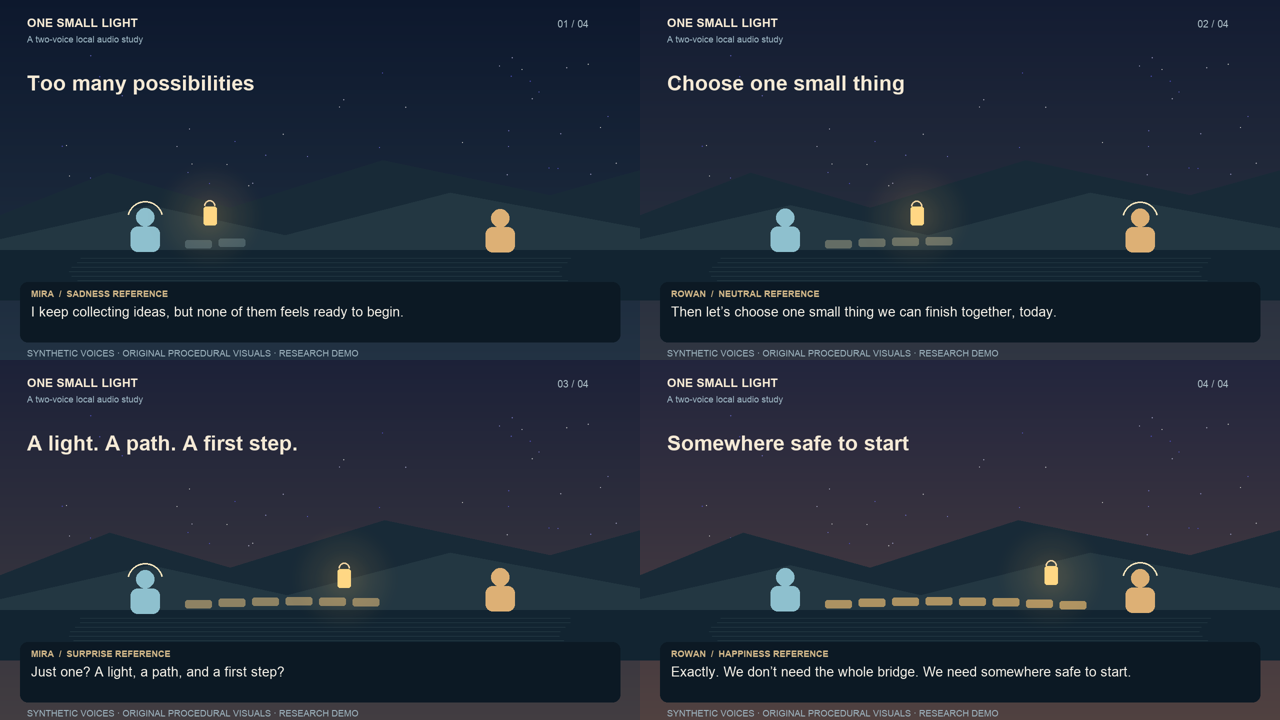

In [4]:
from IPython.display import Video, Image, display
print('Final locally generated short:')
display(Video(filename=str(RUN/'One Small Light.mp4'), embed=True, width=960))
display(Image(filename=str(RUN/'contact-sheet.png'), width=960))

## 7. Evidence, interpretation and limits

The next cell summarizes the measured run. A successful technical result means this specific notebook can integrate the chosen local engines; it does not demonstrate general video generation or guarantee audience appeal. Emotional delivery and speech quality require listening. The prepared research voices and F5 weights retain their existing licensing constraints; this is a private research demonstration, not cleared commercial content.

No prior paper is rewritten and no separate UI is built. All stage originals, processed variants, settings, worker logs and scene timings remain in the run folder. To revise the video, change the script or configuration, rerun the production cell, and inspect a new result.

In [5]:
print('Scene | Speaker | Intended emotion | Enhanced seconds | On-screen seconds')
for entry in result['scenes']:
    scene=entry['scene']
    print(f"{scene['headline']} | {scene['speaker']} | {scene['emotion']} | "
          f"{entry['speech_end']-entry['speech_start']:.3f} | {entry['duration']:.3f}")
print('Technical verdict:', verification['passed'])
print('Listening verdict: user review required; not inferred from reference labels.')

Scene | Speaker | Intended emotion | Enhanced seconds | On-screen seconds
Too many possibilities | Mira | sadness | 4.917 | 5.792
Choose one small thing | Rowan | neutral | 4.672 | 5.542
A light. A path. A first step. | Mira | surprise | 2.709 | 3.583
Somewhere safe to start | Rowan | happiness | 5.141 | 6.000
Technical verdict: True
Listening verdict: user review required; not inferred from reference labels.


## 8. Observed outcome and conclusion

The corrected notebook produced **One Small Light**, a **20.9-second**, four-scene animated dialogue with one male and one female voice. The two speakers use four intended emotional references. Every delivered line comes from its mastered-and-enhanced output; no raw generated take was substituted.

Independent full decoding passed. The final video contains **502 frames** at 24 fps. Its decoded soundtrack correlates **0.99996** with the supplied continuous mix; timing and source hashes agree, motion is visible in decoded frames, and all four audio chains passed independent metering and lineage checks. Earlier papers and Money's configuration/latest pointers remain unchanged.

The pilot exposed a real limit: the default master could not reach its loudness target on the short surprise line while preserving the peak ceiling. A declared fast-attack compressor override corrected that measured failure in a fresh full run. This is a bounded engineering result, not proof that stronger compression sounds better.

**What remains a listening judgment:** perceived emotional delivery, naturalness, pronunciation, voice consistency and artistic quality. This establishes a reproducible local notebook workflow for this short; it does not establish general video generation, monetization, or commercial rights. No separate interface has been built.
